# 使用 sklearn 的 KNN 对 Iris 数据集进行分类

**带注释版** —— 每个步骤都有说明，方便对照理解。

## 0. 导入所需的库

In [1]:
# 导入本次作业需要用到的库
from sklearn.datasets import load_iris                       # 加载鸢尾花数据集
from sklearn.model_selection import train_test_split         # 划分训练集 / 测试集
from sklearn.neighbors import KNeighborsClassifier           # KNN 分类器
from sklearn.metrics import accuracy_score, classification_report  # 评估指标
import matplotlib.pyplot as plt                              # 绘图
# 让 matplotlib 正常显示中文和负号（Windows 用 SimHei）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei'] 
plt.rcParams['axes.unicode_minus'] = False

## 1. 加载 Iris 数据集

In [2]:
iris = load_iris()
X = iris.data      # 特征矩阵，形状 (150, 4)
y = iris.target    # 标签，形状 (150,)

print('特征矩阵 X 形状:', X.shape)
print('标签 y 形状    :', y.shape)
print('四个特征名称   :', iris.feature_names)
print('三个类别名称   :', iris.target_names)

特征矩阵 X 形状: (150, 4)
标签 y 形状    : (150,)
四个特征名称   : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
三个类别名称   : ['setosa' 'versicolor' 'virginica']


## 2. 按 8:2 随机划分训练集与测试集

In [3]:
# test_size=0.2     -> 测试集占 20%，训练集占 80%
# random_state=42   -> 固定随机种子，保证每次运行划分结果一致（可复现）
# stratify=y        -> 分层抽样，保证三个类别在训练/测试集中比例一致
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('训练集样本数:', X_train.shape[0])
print('测试集样本数:', X_test.shape[0])

训练集样本数: 120
测试集样本数: 30


## 3. 创建 5 近邻的 KNN 分类器并训练

In [4]:
# 创建 5 近邻的 KNN 分类器
knn = KNeighborsClassifier(n_neighbors=5)

# 训练模型（对 KNN 而言，fit 就是把这批训练样本存进模型）
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


## 4. 对测试集预测并计算准确率

In [5]:
# 对测试集进行标签预测
y_pred = knn.predict(X_test)

# 用 accuracy_score 计算准确率
acc = accuracy_score(y_test, y_pred)
print('预测标签:', y_pred)
print('真实标签:', y_test)
print('准确率  : %.4f' % acc)

# 也可以用 knn.score() 直接得到准确率，结果完全一样
print('knn.score() 验证:', knn.score(X_test, y_test))

预测标签: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
真实标签: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
准确率  : 1.0000
knn.score() 验证: 1.0


## 5. 打印输出分类报告

In [6]:
# classification_report 给出每个类别的 precision / recall / f1-score / support
print(classification_report(y_test, y_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



## 6. 取 n_neighbors = 1,3,5,7,9 分别建模并记录准确率

In [7]:
# 不同的 k 值会影响模型效果：k 太小对噪声敏感（过拟合），k 太大又过于平滑（欠拟合）
k_list = [1, 3, 5, 7, 9]
acc_list = []

for k in k_list:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    a = model.score(X_test, y_test)
    acc_list.append(a)
    print('n_neighbors = %d, 准确率 = %.4f' % (k, a))

n_neighbors = 1, 准确率 = 0.9667
n_neighbors = 3, 准确率 = 1.0000
n_neighbors = 5, 准确率 = 1.0000
n_neighbors = 7, 准确率 = 0.9667
n_neighbors = 9, 准确率 = 1.0000


## 7. 绘制不同 n_neighbors 取值下的准确率折线图

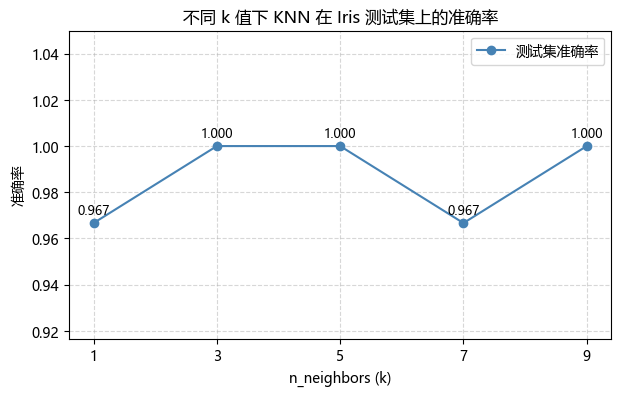

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(k_list, acc_list, marker='o', color='steelblue', label='测试集准确率')

# 在每个数据点上方标出具体数值
for k, a in zip(k_list, acc_list):
    plt.text(k, a + 0.004, '%.3f' % a, ha='center', fontsize=9)

plt.xlabel('n_neighbors (k)')
plt.ylabel('准确率')
plt.title('不同 k 值下 KNN 在 Iris 测试集上的准确率')
plt.xticks(k_list)
plt.ylim(min(acc_list) - 0.05, max(acc_list) + 0.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()